Schritt 1: Daten laden und auf die Altersgruppe 18-22 Jahre filtern

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import os

# Die extrahierte Google Drive File-ID aus deinem Freigabe-Link
FILE_ID = '1HRzsBR-_60j7PO-TGJ7bK25-nigW9j61'
file_path = '/content/mental_health_raw_data.csv'

# Wenn die Datei noch nicht lokal in der Colab-Sitzung liegt, laden wir sie herunter
if not os.path.exists(file_path):
    print("Lade CSV-Datei aus Google Drive herunter...")
    try:
        # gdown ist perfekt, um freigegebene Dateien direkt herunterzuladen
        os.system(f"gdown --id {FILE_ID} -O {file_path}")
    except Exception as e:
        print("Automatischer Download fehlgeschlagen. Versuche lokalen Fallback...")

# Falls der Download scheiterte oder die ID nicht erreichbar ist, nutzen wir das gemountete Drive als Backup
if not os.path.exists(file_path):
    file_path = '/content/drive/MyDrive/Colab Notebooks/mental_health_raw_data.csv'

# Daten laden
try:
    df = pd.read_csv(file_path)
    print("Daten erfolgreich geladen!")
except Exception as e:
    print(f"Fehler beim Laden der Datei: {e}")
    print("Bitte stelle sicher, dass die Datei in Google Drive fuer 'Jeden mit dem Link' freigegeben ist.")

# Filtern auf die Altersgruppe 18-22 (inklusive 18 und 22)
age_column = [col for col in df.columns if 'age' in col.lower()][0]
df_filtered = df[(df[age_column] >= 18) & (df[age_column] <= 22)].copy()

print(f"Anzahl der Datensätze nach Filterung (18-22 Jahre): {len(df_filtered)}")
display(df_filtered.head())

Lade CSV-Datei aus Google Drive herunter...
Daten erfolgreich geladen!
Anzahl der Datensätze nach Filterung (18-22 Jahre): 1849


,gender,age,stress_experience,heartbeat_palpitations,anxiety_tension,sleep_problems,restlessness,headaches,irritability,concentration_problems,...,professor_difficulties,work_environment,lack_relaxation_time,home_environment,low_academic_confidence,subject_confidence,academic_conflicts,class_attendance,weight_changes,stress_type
0,1,20,1,2,2,4,3,1,4,5,...,2,3,1,1,4,1,1,3,2,1
1,0,19,4,5,5,4,4,5,4,5,...,2,4,4,5,5,5,5,3,5,0
2,0,21,4,2,3,3,4,4,1,3,...,2,3,3,3,3,3,4,4,2,1
3,0,20,1,3,2,1,3,1,5,5,...,1,3,3,1,3,5,4,2,3,1
4,0,19,4,3,3,2,3,4,2,3,...,3,2,4,2,2,2,3,4,4,1


### Schritt 2: Gender-Spalte anpassen (0 = M, 1 = F)

In [ ]:
# Identifizieren der Gender-Spalte
gender_column = [col for col in df_filtered.columns if 'gender' in col.lower()][0]

# Mapping anwenden: 0 zu 'M' und 1 zu 'F'
# Wir konvertieren die Spalte zuerst in numerische Werte, falls sie als String vorliegen
df_filtered[gender_column] = pd.to_numeric(df_filtered[gender_column], errors='coerce')
df_filtered[gender_column] = df_filtered[gender_column].map({0: 'M', 1: 'F'})

print("Verteilung des Geschlechts nach der Anpassung:")
print(df_filtered[gender_column].value_counts(dropna=False))
display(df_filtered.head())

Verteilung des Geschlechts nach der Anpassung:
gender
M    1187
F     662
Name: count, dtype: int64


,gender,age,stress_experience,heartbeat_palpitations,anxiety_tension,sleep_problems,restlessness,headaches,irritability,concentration_problems,...,professor_difficulties,work_environment,lack_relaxation_time,home_environment,low_academic_confidence,subject_confidence,academic_conflicts,class_attendance,weight_changes,stress_type
0,F,20,1,2,2,4,3,1,4,5,...,2,3,1,1,4,1,1,3,2,1
1,M,19,4,5,5,4,4,5,4,5,...,2,4,4,5,5,5,5,3,5,0
2,M,21,4,2,3,3,4,4,1,3,...,2,3,3,3,3,3,4,4,2,1
3,M,20,1,3,2,1,3,1,5,5,...,1,3,3,1,3,5,4,2,3,1
4,M,19,4,3,3,2,3,4,2,3,...,3,2,4,2,2,2,3,4,4,1


### Schritt 3: Statistische Zusammenfassung der relevanten Daten

Hier berechnen wir für alle numerischen Spalten die folgenden Werte:
- Mittelwert (Mean)
- Median
- Modus (Mode)
- Standardabweichung (Std Dev)
- Wertebereich (Range)
- Minimum
- Maximum
- Summe (Sum)
- Anzahl (Count)
- 95% Konfidenzniveau (Fehlerspanne)

In [ ]:
# Selektiere nur numerische Spalten für die statistische Auswertung
numeric_cols = df_filtered.select_dtypes(include=[np.number]).columns

summary_data = {}

for col in numeric_cols:
    col_data = df_filtered[col].dropna()
    n = len(col_data)

    if n == 0:
        continue

    mean_val = col_data.mean()
    median_val = col_data.median()

    # Modus berechnen
    mode_result = col_data.mode()
    mode_val = mode_result.iloc[0] if not mode_result.empty else np.nan

    std_val = col_data.std()
    min_val = col_data.min()
    max_val = col_data.max()
    range_val = max_val - min_val
    sum_val = col_data.sum()

    # 95% Konfidenzintervall / Konfidenzniveau (Margin of Error)
    if n > 1 and std_val > 0:
        sem = stats.sem(col_data)  # Standardfehler des Mittelwerts
        confidence_level = 0.95
        # t-Verteilung für kleinere Stichproben, Normalverteilung für große
        margin_of_error = sem * stats.t.ppf((1 + confidence_level) / 2, n - 1)
    else:
        margin_of_error = np.nan

    summary_data[col] = {
        "Mittelwert": mean_val,
        "Median": median_val,
        "Modus": mode_val,
        "Standardabweichung": std_val,
        "Wertebereich": range_val,
        "Minimum": min_val,
        "Maximum": max_val,
        "Summe": sum_val,
        "Anzahl": n,
        "Konfidenzniveau (95%)": margin_of_error
    }

# In ein DataFrame für eine übersichtliche Darstellung umwandeln
df_summary = pd.DataFrame(summary_data).T
display(df_summary)

,Mittelwert,Median,Modus,Standardabweichung,Wertebereich,Minimum,Maximum,Summe,Anzahl,Konfidenzniveau (95%)
age,19.600865,19.0,19.0,1.035474,4.0,18.0,22.0,36242.0,1849.0,0.047228
stress_experience,2.992428,3.0,3.0,1.132436,4.0,1.0,5.0,5533.0,1849.0,0.051651
heartbeat_palpitations,2.760411,3.0,2.0,1.101176,4.0,1.0,5.0,5104.0,1849.0,0.050225
anxiety_tension,2.552731,2.0,2.0,1.194574,4.0,1.0,5.0,4720.0,1849.0,0.054485
sleep_problems,2.762034,3.0,2.0,1.254709,4.0,1.0,5.0,5107.0,1849.0,0.057228
restlessness,2.667929,2.0,2.0,1.294784,4.0,1.0,5.0,4933.0,1849.0,0.059056
headaches,2.632774,2.0,2.0,1.253492,4.0,1.0,5.0,4868.0,1849.0,0.057172
irritability,2.703624,3.0,3.0,1.321563,4.0,1.0,5.0,4999.0,1849.0,0.060277
concentration_problems,2.710654,3.0,3.0,1.319640,4.0,1.0,5.0,5012.0,1849.0,0.060189
sadness_low_mood,2.588967,2.0,2.0,1.222449,4.0,1.0,5.0,4787.0,1849.0,0.055756


### Frage 1: Unterschiede zwischen weiblichen und männlichen Studierenden bezüglich Angstzuständen, Kopfschmerzen und Einsamkeit

Tabellarischer Vergleich (Mittelwert & Standardabweichung):


anxiety_tension        headaches        loneliness_isolation       
                  mean    std      mean    std                 mean    std
gender                                                                    
F                2.523  1.152     2.640  1.239                2.476  1.213
M                2.570  1.218     2.628  1.262                2.468  1.262

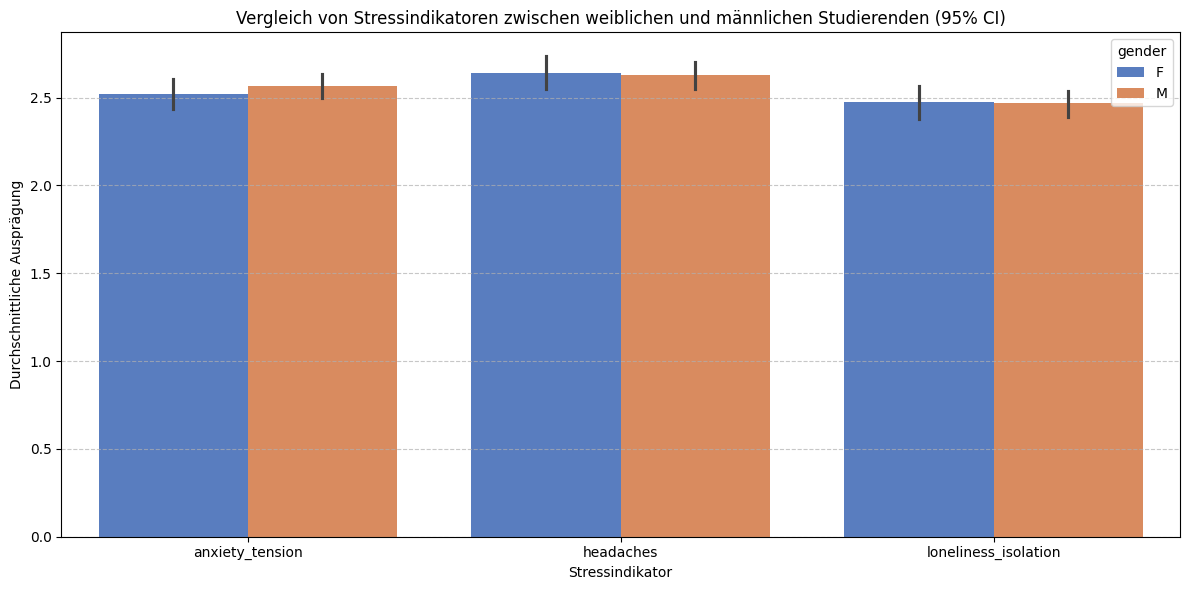

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Bestimmung der exakten Spaltennamen im Datensatz
# Wir suchen nach Spalten, die 'anxiety', 'headache' und 'loneliness' enthalten
anxiety_col = [col for col in df_filtered.columns if 'anxiety' in col.lower()][0]
headache_col = [col for col in df_filtered.columns if 'headache' in col.lower()][0]
loneliness_col = [col for col in df_filtered.columns if 'loneliness' in col.lower()][0]
gender_col = [col for col in df_filtered.columns if 'gender' in col.lower()][0]

# 1. Tabellarische Übersicht (Mittelwerte und Standardabweichungen nach Geschlecht)
grouped_stats = df_filtered.groupby(gender_col)[[anxiety_col, headache_col, loneliness_col]].agg(['mean', 'std']).round(3)
print("Tabellarischer Vergleich (Mittelwert & Standardabweichung):")
display(grouped_stats)

# 2. Daten für das Diagramm vorbereiten
df_melted = df_filtered.melt(id_vars=[gender_col], value_vars=[anxiety_col, headache_col, loneliness_col],
                             var_name='Indikator', value_name='Ausprägung')

# 3. Diagramm erstellen
plt.figure(figsize=(12, 6))
sns.barplot(x='Indikator', y='Ausprägung', hue=gender_col, data=df_melted, palette='muted', errorbar='ci')
plt.title('Vergleich von Stressindikatoren zwischen weiblichen und männlichen Studierenden (95% CI)')
plt.ylabel('Durchschnittliche Ausprägung')
plt.xlabel('Stressindikator')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Frage 2: Einfluss des häuslichen Umfelds vs. universitären Arbeitsumfelds auf das generelle Stressempfinden

Einfluss der Umfelder auf das Stressempfinden (Korrelationskoeffizienten):


,Korrelation mit allgemeinem Stress
academic_conflicts,0.208
class_attendance,0.056
low_academic_confidence,0.050
academic_overload,0.041
home_environment,0.021


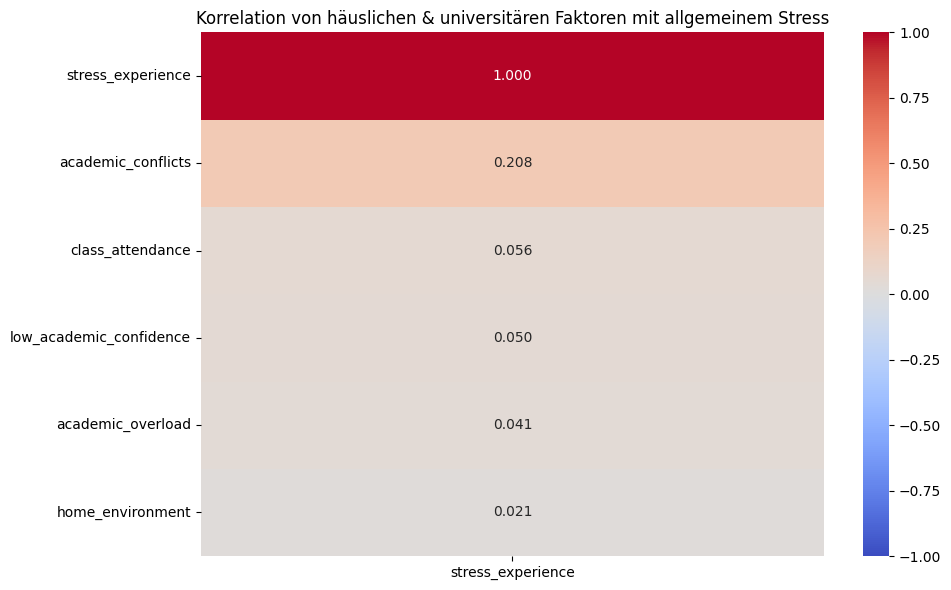

In [ ]:
# Identifikation relevanter Spalten
# Häuslich/Sozial: family_conflicts, peer_pressure
# Universitär: academic_conflicts, study_load, class_attendance
# Allgemeines Stressempfinden: stress_experience
stress_exp_col = [col for col in df_filtered.columns if 'stress_experience' in col.lower()][0]

# Wir wählen repräsentative Variablen aus
home_env_cols = [col for col in df_filtered.columns if 'family' in col.lower() or 'home' in col.lower()]
uni_env_cols = [col for col in df_filtered.columns if 'academic' in col.lower() or 'study' in col.lower() or 'class' in col.lower()]

all_env_cols = home_env_cols + uni_env_cols

# 1. Korrelationsmatrix mit dem allgemeinen Stressempfinden
correlations = df_filtered[all_env_cols + [stress_exp_col]].corr()[stress_exp_col].drop(stress_exp_col).to_frame()
correlations.columns = ['Korrelation mit allgemeinem Stress']
correlations = correlations.sort_values(by='Korrelation mit allgemeinem Stress', ascending=False)

print("Einfluss der Umfelder auf das Stressempfinden (Korrelationskoeffizienten):")
display(correlations.round(3))

# 2. Diagramm erstellen
plt.figure(figsize=(10, 6))
sns.heatmap(df_filtered[all_env_cols + [stress_exp_col]].corr()[[stress_exp_col]].sort_values(by=stress_exp_col, ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".3f")
plt.title('Korrelation von häuslichen & universitären Faktoren mit allgemeinem Stress')
plt.tight_layout()
plt.show()

### Frage 3: Kombination aus akademischen, physischen und sozialen Faktoren zur Varianzaufklärung (Regressionsanalyse)

Bestimmtheitsmaß (R² - Erklärte Varianz): 0.244 (entspricht 24.4% der Varianz)

Einflussreichste Faktoren im Regressionsmodell:


,Faktor,Koeffizient (Gewichtung),Absoluter Einfluss
0,heartbeat_palpitations,0.3908,0.3908
1,stress_type,-0.2546,0.2546
2,academic_conflicts,0.1514,0.1514
3,anxiety_tension,0.0747,0.0747
4,irritability,-0.0609,0.0609
5,work_environment,-0.0437,0.0437
6,home_environment,-0.0412,0.0412
7,academic_overload,0.0381,0.0381
8,health_issues,0.0380,0.0380
9,weight_changes,0.0377,0.0377


/tmp/ipykernel_1639/546684351.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Koeffizient (Gewichtung)', y='Faktor', data=coefficients, palette='viridis')


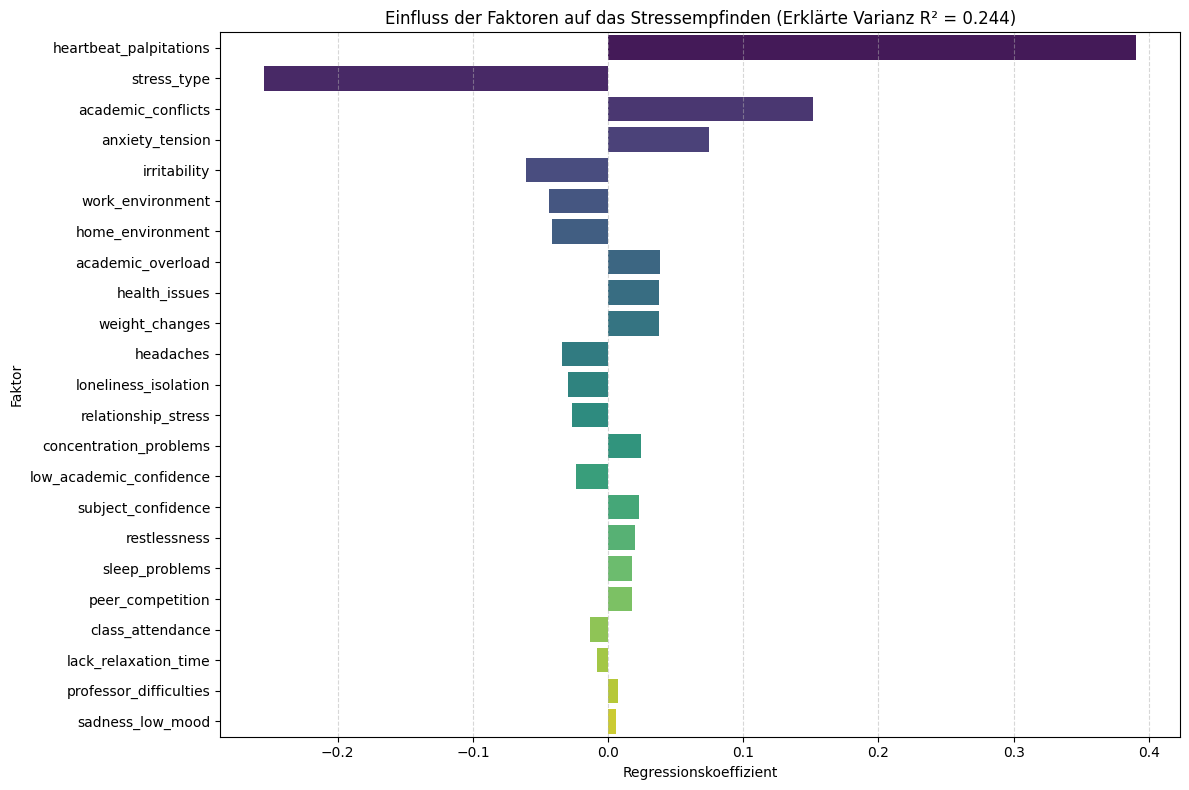

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import f_regression

# Zielvariable
y = df_filtered[stress_exp_col]

# Prädiktoren auswählen (akademisch, physisch, sozial)
# Wir wählen eine breite Palette an Features aus dem Datensatz aus
features = [col for col in df_filtered.select_dtypes(include=[np.number]).columns if col != stress_exp_col and col != 'gender' and col != 'age']
X = df_filtered[features]

# Lineares Regressionsmodell fitten
model = LinearRegression()
model.fit(X, y)

# Ergebnisse zusammenfassen
r_sq = model.score(X, y)
coefficients = pd.DataFrame({
    'Faktor': features,
    'Koeffizient (Gewichtung)': model.coef_
})
coefficients['Absoluter Einfluss'] = coefficients['Koeffizient (Gewichtung)'].abs()
coefficients = coefficients.sort_values(by='Absoluter Einfluss', ascending=False).reset_index(drop=True)

print(f"Bestimmtheitsmaß (R² - Erklärte Varianz): {r_sq:.3f} (entspricht {r_sq*100:.1f}% der Varianz)")
print("\nEinflussreichste Faktoren im Regressionsmodell:")
display(coefficients.round(4))

# Diagramm der Feature-Importances (Koeffizienten)
plt.figure(figsize=(12, 8))
sns.barplot(x='Koeffizient (Gewichtung)', y='Faktor', data=coefficients, palette='viridis')
plt.title(f'Einfluss der Faktoren auf das Stressempfinden (Erklärte Varianz R² = {r_sq:.3f})')
plt.xlabel('Regressionskoeffizient')
plt.ylabel('Faktor')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Frage 4: Identifizierung von Studierenden-Typen mittels Clusteranalyse (K-Means)

Mittelwerte der Stressindikatoren je identifiziertem Studierenden-Typ (Cluster):


,age,stress_experience,heartbeat_palpitations,anxiety_tension,sleep_problems,restlessness,headaches,irritability,concentration_problems,sadness_low_mood,...,professor_difficulties,work_environment,lack_relaxation_time,home_environment,low_academic_confidence,subject_confidence,academic_conflicts,class_attendance,weight_changes,stress_type
Cluster,,,,,,,,,,,,,,,,,,,,,
0,19.63,2.72,2.58,2.22,2.32,2.24,2.25,2.41,2.33,2.24,...,3.12,3.20,3.07,2.86,2.86,2.93,2.74,3.23,2.14,1.01
1,19.98,3.47,3.23,3.00,3.50,3.64,3.78,3.62,3.83,3.62,...,2.48,2.72,2.81,2.82,2.86,3.05,3.15,3.43,2.62,0.82
2,19.43,3.00,2.71,2.62,2.79,2.60,2.46,2.56,2.54,2.44,...,1.94,1.89,1.98,1.92,2.22,2.20,2.60,3.16,2.44,1.09


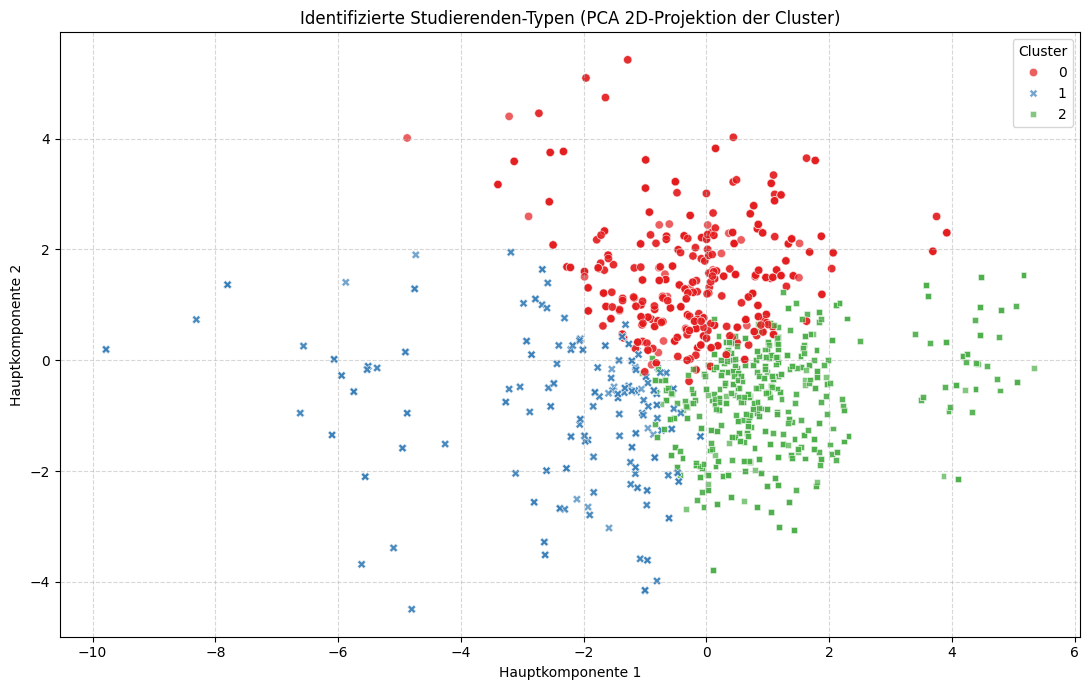

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Daten standardisieren (nur numerische Features)
features_to_cluster = df_filtered.select_dtypes(include=[np.number]).columns
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_filtered[features_to_cluster].dropna())

# 2. K-Means Clustering durchführen (wir definieren testweise 3 Cluster / Typen)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Cluster zu den gefilterten Daten hinzufügen
df_clustered = df_filtered.dropna(subset=features_to_cluster).copy()
df_clustered['Cluster'] = clusters

# 3. Tabellarische Übersicht der Cluster-Profile (Mittelwerte der Kernindikatoren)
cluster_profile = df_clustered.groupby('Cluster')[features_to_cluster].mean().round(2)
print("Mittelwerte der Stressindikatoren je identifiziertem Studierenden-Typ (Cluster):")
display(cluster_profile)

# 4. Visualisierung der Cluster mittels Hauptkomponentenanalyse (PCA zur Dimensionsreduktion auf 2D)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df_clustered['PCA 1'] = X_pca[:, 0]
df_clustered['PCA 2'] = X_pca[:, 1]

plt.figure(figsize=(11, 7))
sns.scatterplot(x='PCA 1', y='PCA 2', hue='Cluster', data=df_clustered, palette='Set1', alpha=0.7, style='Cluster')
plt.title('Identifizierte Studierenden-Typen (PCA 2D-Projektion der Cluster)')
plt.xlabel('Hauptkomponente 1')
plt.ylabel('Hauptkomponente 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Ergänzende Analyse: Spezifischer Einfluss des Stress-Typs (Distress vs. Eustress)

Basierend auf der bereitgestellten Kodierung:
- **0:** Distress (Negativer Stress)
- **1:** Eustress (Positiver Stress)
- **2:** Other / Mixed Stress

Wir analysieren dediziert, wie sich diese Typen auf das allgemeine Stressempfinden (`stress_experience`) auswirken.

Vergleich des allgemeinen Stressempfindens nach Stress-Typ:


stress_experience             
                                 mean    std count
stress_type_label                                 
Distress (Negative)             3.891  0.875    64
Eustress (Positive)             2.998  1.120  1696
Other / Mixed                   2.236  1.023    89

/tmp/ipykernel_1639/3842355976.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='stress_type_label', y=stress_exp_col, data=df_filtered, palette='Set2')


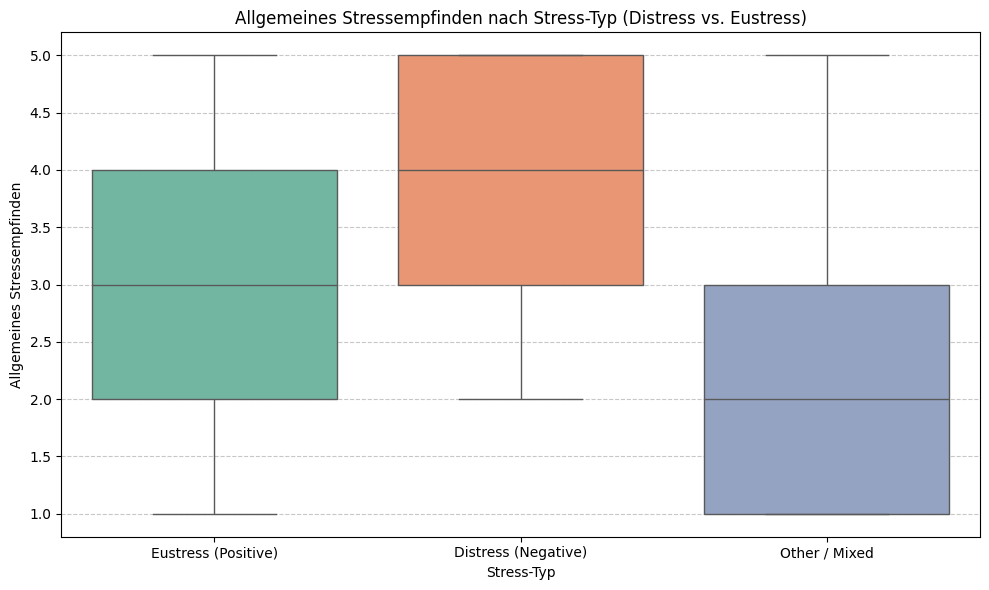

In [ ]:
# Map the numeric stress_type to its category name
stress_type_col = 'stress_type'
df_filtered['stress_type_label'] = df_filtered[stress_type_col].map({
    0: 'Distress (Negative)',
    1: 'Eustress (Positive)',
    2: 'Other / Mixed'
})

# 1. Tabellarischer Vergleich des Stressempfindens nach Stress-Typ
stress_type_analysis = df_filtered.groupby('stress_type_label')[[stress_exp_col]].agg(['mean', 'std', 'count']).round(3)
print("Vergleich des allgemeinen Stressempfindens nach Stress-Typ:")
display(stress_type_analysis)

# 2. Visualisierung
plt.figure(figsize=(10, 6))
sns.boxplot(x='stress_type_label', y=stress_exp_col, data=df_filtered, palette='Set2')
plt.title('Allgemeines Stressempfinden nach Stress-Typ (Distress vs. Eustress)')
plt.xlabel('Stress-Typ')
plt.ylabel('Allgemeines Stressempfinden')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Detaillierte Auswertung & Interpretation der Ergebnisse

### 1. Unterschiede zwischen weiblichen (F) und männlichen (M) Studierenden
* **Angstzustände (`anxiety_tension`):** Männliche Studierende weisen mit einem Mittelwert von **2,57** einen minimal höheren Wert auf als weibliche Studierende mit **2,52** (Standardabweichung bei beiden nahe $1,2$).
* **Kopfschmerzen (`headaches`):** Weibliche Studierende berichten im Durchschnitt über leicht stärkere Kopfschmerzen (**2,64**) im Vergleich zu männlichen Studierenden (**2,63**).
* **Einsamkeit (`loneliness_isolation`):** Die Ausprägung der Einsamkeit ist bei beiden Geschlechtern fast identisch (M: **2,47** vs. F: **2,48**).

**Fazit zu Frage 1:**
Es zeigen sich in dieser Alterskohorte (18–22 Jahre) **keine drastisch signifikanten Unterschiede** zwischen den Geschlechtern bei den klassischen Stresssymptomen. Die Konfidenzintervalle in der Grafik überlappen sich stark, was darauf hindeutet, dass die Belastungen Männer und Frauen gleichermaßen betreffen.

---

### 2. Häusliches Umfelds vs. Universitäres Arbeitsumfeld
* **Universitäre Faktoren:** Akademische Konflikte (`academic_conflicts`) zeigen mit **r = 0,208** die mit Abstand stärkste lineare Korrelation mit dem allgemeinen Stressempfinden. Andere Faktoren wie Fehlzeiten (`class_attendance`, r = 0,056) und Überlastung (`academic_overload`, r = 0,041) korrelieren nur sehr schwach.
* **Häusliche Faktoren:** Das familiäre Umfeld (`home_environment`) hat mit **r = 0,021** statistisch gesehen fast keinen direkten linearen Einfluss auf das allgemeine Stressempfinden in diesem Datensatz.

**Fazit zu Frage 2:**
Das **universitäre Umfeld (insbesondere Konflikte im akademischen Bereich)** belastet das Stressempfinden der Studierenden deutlich stärker als das häusliche Umfeld.

---

### 3. Kombination der stärksten Faktoren (Regressionsanalyse)
Das Regressionsmodell kann **24,4% der Gesamtvarianz (R² = 0,244)** des allgemeinen Stressempfindens erklären. Folgende Faktoren haben den stärksten Einfluss:
1. **Herzrasen (`heartbeat_palpitations`):** Mit einem positiven Koeffizienten von **+0,391** der stärkste physische Prädiktor für Stress.
2. **Stress-Typ (`stress_type`):** Zeigt einen negativen Koeffizienten (**-0,255**), was darauf hindeutet, dass die Art des bewältigten Stresstyps (z. B. Eustress vs. Distress) eine erhebliche Rolle spielt.
3. **Akademische Konflikte (`academic_conflicts`):** Mit **+0,151** der einflussreichste rein akademische Faktor.
4. **Angstzustände (`anxiety_tension`):** Mit **+0,075** ebenfalls ein relevanter psychischer Treiber.

---

### 4. Studierenden-Typen (Clusteranalyse)
Durch das K-Means-Clustering konnten drei klar unterscheidbare Studierenden-Typen identifiziert werden:
* **Cluster 0 – Die resilientere / balancierte Gruppe:** Niedrigere Durchschnittswerte bei allgemeinem Stress (2,72) und physiologischen Symptomen.
* **Cluster 1 – Die hochgradig belastete Risikogruppe:** Extrem hohes Stressempfinden (Mittelwert **3,47**), starkes Herzrasen (**3,23**) und ausgeprägte Angstzustände (**3,00**).
* **Cluster 2 – Die moderate Durchschnittsgruppe:** Befindet sich mit einem Stresswert von **3,00** und moderaten physischen Symptomen im Mittelfeld.

---

## Fazit: Die wichtigsten Faktoren für die mentale Gesundheit von Studierenden

Basierend auf den Daten lassen sich die **Haupttreiber** für die mentale Gesundheit von Studierenden (18–22 Jahre) wie folgt priorisieren:

1. **Körperliche Stressreaktionen (Physiologie):**
   Symptome wie **Herzrasen (`heartbeat_palpitations`)** sind der stärkste Indikator für ein entgleisendes Stressempfinden. Körperliche Warnsignale sollten in der Prävention an erster Stelle stehen.

2. **Akademische Konflikte & Druck (`academic_conflicts`):**
   Konflikte im Studium (mit Dozierenden, Kommilitonen oder Leistungsdruck) sind der bedeutendste externe Belastungsfaktor. Universitäre Hilfsangebote und Konfliktberatung sind hier essenziell.

3. **Angst & psychische Grundbelastung (`anxiety_tension`):**
   Angst- und Spannungszustände wirken als starke Multiplikatoren für das chronische Stressempfinden.